# Предсказания для сложных примеров

Ноутбук использует веса `unet.pt` и список путей из `hard_examples.txt`. Архитектура U-Net, подготовка RGB-изображений, тайлинг, перекрытие тайлов, autocast и порог вероятности повторяют baseline. Постобработка кривых взята из `rogii-baseline-unet-2gpu-local-fix-union.ipynb`.

Для каждого изображения в `predictions_analysis_results/` сохраняются полноразмерный PNG с кривыми поверх оригинала и JSON с предсказанными полилиниями. В ноутбуке показывается уменьшенная копия итогового изображения.


In [1]:
import copy
import json
import os
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageDraw
from IPython.display import display

from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from skimage.measure import approximate_polygon
from skimage.morphology import skeletonize

Image.MAX_IMAGE_PIXELS = None

EXAMPLES_FILE = Path("hard_examples.txt")
WEIGHTS_PATH = Path(os.environ.get("ROGII_WEIGHTS", "unet.pt")).expanduser().resolve()
RESULTS_DIR = Path("predictions_analysis_results")

if not EXAMPLES_FILE.is_file():
    raise FileNotFoundError(f"Не найден файл со списком примеров: {EXAMPLES_FILE.resolve()}")

example_paths = [
    Path(line.strip()).expanduser()
    for line in EXAMPLES_FILE.read_text(encoding="utf-8-sig").splitlines()
    if line.strip() and not line.lstrip().startswith("#")
]
if not example_paths:
    raise ValueError(f"В {EXAMPLES_FILE} нет путей к изображениям")

missing_paths = [str(path) for path in example_paths if not path.is_file()]
if missing_paths:
    raise FileNotFoundError("Не найдены изображения из hard_examples.txt:\n" + "\n".join(missing_paths))
if not WEIGHTS_PATH.is_file():
    raise FileNotFoundError(f"Не найдены веса модели: {WEIGHTS_PATH}")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Изображений: {len(example_paths)}")
print(f"Веса: {WEIGHTS_PATH}")
print(f"Результаты: {RESULTS_DIR.resolve()}")

Изображений: 1
Веса: C:\Users\333\diploma\unet.pt
Результаты: C:\Users\333\diploma\predictions_analysis_results


In [2]:
def block(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1, bias=False),
        nn.BatchNorm2d(o),
        nn.ReLU(True),
        nn.Conv2d(o, o, 3, padding=1, bias=False),
        nn.BatchNorm2d(o),
        nn.ReLU(True),
    )


class UNet(nn.Module):
    def __init__(s, ch=(16, 32, 64, 128, 192)):
        super().__init__()
        s.enc = nn.ModuleList(
            [block(3, ch[0])] + [block(ch[k], ch[k + 1]) for k in range(len(ch) - 1)]
        )
        s.dec = nn.ModuleList(
            [block(ch[k + 1] + ch[k], ch[k]) for k in range(len(ch) - 1)]
        )
        s.out = nn.Conv2d(ch[0], 1, 1)

    def forward(s, x):
        x = (x - 0.5) / 0.5
        f = []
        for k, e in enumerate(s.enc):
            x = e(x if k == 0 else F.max_pool2d(x, 2))
            f.append(x)
        x = f[-1]
        for k in range(len(s.dec) - 1, -1, -1):
            x = F.interpolate(x, size=f[k].shape[-2:], mode="bilinear", align_corners=False)
            x = s.dec[k](torch.cat([x, f[k]], 1))
        return s.out(x)


dev = "cuda:0" if torch.cuda.is_available() else "cpu"
GPUS = (
    [int(g) for g in os.environ["ROGII_GPUS"].split(",")]
    if os.environ.get("ROGII_GPUS")
    else list(range(torch.cuda.device_count()))
)
amp = torch.bfloat16 if (dev != "cpu" and torch.cuda.is_bf16_supported()) else torch.float16
torch.manual_seed(0)
torch.backends.cudnn.benchmark = True

net = UNet().to(dev)
net.load_state_dict(torch.load(WEIGHTS_PATH, map_location=dev))
net.eval()
devices = [f"cuda:{g}" for g in GPUS] or ["cpu"]
nets = [copy.deepcopy(net).to(device).eval() for device in devices]

print(f"Устройство загрузки модели: {dev}; устройства инференса: {devices}")

Устройство загрузки модели: cuda:0; устройства инференса: ['cuda:0']


In [3]:
TILE, OVERLAP, THRESHOLD = 1024, 32, 0.15
MIN_LINK, MIN_TRACK, MAX_CURVES = 20, 100, 300
GAP_MAX, COL_MAX = 1500, 110 # 110

def curves_from_mask(mask, image):
    H, W = mask.shape; ys, xs = np.nonzero(skeletonize(mask))
    if len(ys) < MIN_TRACK: return []
    key = ys.astype(np.int64) * W + xs; n = len(key); edges = []
    for dy, dx in ((0, 1), (1, -1), (1, 0), (1, 1)):
        ok = (xs + dx >= 0) & (xs + dx < W) & (ys + dy < H); nk = key[ok] + dy * W + dx
        pos = np.searchsorted(key, nk); pos[pos >= n] = n - 1; hit = key[pos] == nk
        edges.append((np.flatnonzero(ok)[hit], pos[hit]))
    a = np.concatenate([e[0] for e in edges]); b = np.concatenate([e[1] for e in edges])
    deg = np.bincount(a, minlength=n) + np.bincount(b, minlength=n)
    nj = (deg[a] < 3) & (deg[b] < 3)
    ca, cb = a[nj], b[nj]
    chain_graph = coo_matrix((np.ones(2 * len(ca), np.int8), (np.r_[ca, cb], np.r_[cb, ca])), shape=(n, n)).tocsr()
    chain_graph.sort_indices()
    _, chain = connected_components(chain_graph, directed=False)
    chain_deg = np.diff(chain_graph.indptr)
    order = np.argsort(chain, kind="stable"); groups = np.split(order, np.flatnonzero(np.diff(chain[order])) + 1)
    segments = []
    for g in groups:
        if len(g) < 3: continue
        ends = g[chain_deg[g] == 1]; closed = len(ends) == 0
        start_nodes = g if closed else ends
        start = int(start_nodes[np.lexsort((xs[start_nodes], ys[start_nodes]))[0]])
        path, prev, cur = [start], -1, start
        while True:
            lo, hi = chain_graph.indptr[cur], chain_graph.indptr[cur + 1]
            neighbours = chain_graph.indices[lo:hi]
            neighbours = neighbours[neighbours != prev]
            if len(neighbours) == 0: break
            nxt = int(neighbours[0])
            if nxt == start: break
            path.append(nxt); prev, cur = cur, nxt
        if len(path) != len(g): continue
        if closed: path.append(start)
        path = np.asarray(path)
        pts = approximate_polygon(np.column_stack([xs[path], ys[path]]).astype(float), 1.0)
        if len(pts) < 2: continue
        extrema = g[np.lexsort((xs[g], ys[g]))]
        top, bottom = extrema[0], extrema[-1]
        segments.append((pts, float(ys[top]), float(xs[top]), float(ys[bottom]), float(xs[bottom]),
                         np.median(image[ys[g], xs[g], :3].astype(float), axis=0), len(g)))  # Use median for a robust color estimate.
                        # image[ys[g], xs[g], :3].astype(float).mean(axis=0), len(g)))
    m = len(segments)
    if m == 0: return []
    # Link individual segments instead of original connected components.
    ty = np.array([s[1] for s in segments]); tx = np.array([s[2] for s in segments])
    by = np.array([s[3] for s in segments]); bx = np.array([s[4] for s in segments])
    colour = np.stack([s[5] for s in segments])
    by_top = np.argsort(ty); tys = ty[by_top]; cand = []
    for i in range(m):
        js = by_top[np.searchsorted(tys, by[i] - 15):np.searchsorted(tys, by[i] + GAP_MAX, side="right")] # js = by_top[np.searchsorted(tys, by[i] - 15):np.searchsorted(tys, by[i] + GAP_MAX, side="right")]
        js = js[js != i]
        if len(js) == 0: continue
        gap = np.maximum(ty[js] - by[i], 0); dx = np.abs(tx[js] - bx[i])
        cd = np.linalg.norm(colour[js] - colour[i], axis=1)
        valid = (dx <= 500) & (cd <= COL_MAX)  # Use a fixed horizontal limit.
        cand += [(d + 0.05 * g_ + 5.0 * c, i, int(j)) for j, g_, d, c in zip(js[valid], gap[valid], dx[valid], cd[valid])]
    cand.sort(); root = list(range(m)); next_seg, prev_seg = {}, {}
    def find_root(x):
        while root[x] != x: root[x] = root[root[x]]; x = root[x]
        return x
    for _, i, j in cand:
        if i in next_seg or j in prev_seg: continue
        ri, rj = find_root(i), find_root(j)
        if ri == rj: continue
        root[ri] = rj; next_seg[i] = j; prev_seg[j] = i
    tracks = []
    for i in range(m):
        if i in prev_seg: continue
        track, cur = [], i
        while True:
            track.append(cur)
            if cur not in next_seg: break
            cur = next_seg[cur]
        tracks.append(track)
    items = sorted([(sum(segments[s][6] for s in v), v) for v in tracks
                    if sum(segments[s][6] for s in v) >= MIN_TRACK], key=lambda t: -t[0])
    out = []
    for _, v in items[:MAX_CURVES]:
        cur = []
        for s in v:
            if cur: cur.append(None)
            cur += np.rint(segments[s][0]).astype(int).tolist()
        out.append(cur)
    return out

In [4]:
# TILE, OVERLAP, THRESHOLD = 1024, 32, 0.15
# MIN_LINK, MIN_TRACK, MAX_CURVES = 20, 100, 300
# GAP_MAX, COL_MAX = 1500, 20

# def curves_from_mask(mask, image):
#     H, W = mask.shape
#     ys, xs = np.nonzero(skeletonize(mask))
#     if len(ys) < MIN_TRACK:
#         return []
#     key = ys.astype(np.int64) * W + xs
#     n = len(key)
#     edges = []
#     for dy, dx in ((0, 1), (1, -1), (1, 0), (1, 1)):
#         ok = (xs + dx >= 0) & (xs + dx < W) & (ys + dy < H)
#         nk = key[ok] + dy * W + dx
#         pos = np.searchsorted(key, nk)
#         pos[pos >= n] = n - 1
#         hit = key[pos] == nk
#         edges.append((np.flatnonzero(ok)[hit], pos[hit]))
#     a = np.concatenate([edge[0] for edge in edges])
#     b = np.concatenate([edge[1] for edge in edges])
#     deg = np.bincount(a, minlength=n) + np.bincount(b, minlength=n)
#     non_junction = (deg[a] < 3) & (deg[b] < 3)
#     ca, cb = a[non_junction], b[non_junction]
#     chain_graph = coo_matrix(
#         (np.ones(2 * len(ca), np.int8), (np.r_[ca, cb], np.r_[cb, ca])),
#         shape=(n, n),
#     ).tocsr()
#     chain_graph.sort_indices()
#     _, chain = connected_components(chain_graph, directed=False)
#     chain_deg = np.diff(chain_graph.indptr)
#     order = np.argsort(chain, kind="stable")
#     groups = np.split(order, np.flatnonzero(np.diff(chain[order])) + 1)

#     segments = []
#     for group in groups:
#         if len(group) < 3:
#             continue
#         ends = group[chain_deg[group] == 1]
#         closed = len(ends) == 0
#         start_nodes = group if closed else ends
#         start = int(start_nodes[np.lexsort((xs[start_nodes], ys[start_nodes]))[0]])
#         path, prev, cur = [start], -1, start
#         while True:
#             lo, hi = chain_graph.indptr[cur], chain_graph.indptr[cur + 1]
#             neighbours = chain_graph.indices[lo:hi]
#             neighbours = neighbours[neighbours != prev]
#             if len(neighbours) == 0:
#                 break
#             nxt = int(neighbours[0])
#             if nxt == start:
#                 break
#             path.append(nxt)
#             prev, cur = cur, nxt
#         if len(path) != len(group):
#             continue
#         if closed:
#             path.append(start)
#         path = np.asarray(path)
#         points = approximate_polygon(np.column_stack([xs[path], ys[path]]).astype(float), 1.0)
#         if len(points) < 2:
#             continue
#         extrema = group[np.lexsort((xs[group], ys[group]))]
#         top, bottom = extrema[0], extrema[-1]
#         segments.append(
#             (
#                 points,
#                 float(ys[top]),
#                 float(xs[top]),
#                 float(ys[bottom]),
#                 float(xs[bottom]),
#                 image[ys[group], xs[group], :3].astype(float).mean(axis=0),
#                 len(group),
#             )
#         )

#     m = len(segments)
#     if m == 0:
#         return []

#     ty = np.array([segment[1] for segment in segments])
#     tx = np.array([segment[2] for segment in segments])
#     by = np.array([segment[3] for segment in segments])
#     bx = np.array([segment[4] for segment in segments])
#     colour = np.stack([segment[5] for segment in segments])
#     by_top = np.argsort(ty)
#     tys = ty[by_top]
#     candidates = []
#     for i in range(m):
#         js = by_top[
#             np.searchsorted(tys, by[i]) : np.searchsorted(tys, by[i] + GAP_MAX, side="right")
#         ]
#         js = js[js != i]
#         if len(js) == 0:
#             continue
#         gap = np.maximum(ty[js] - by[i], 0)
#         dx = np.abs(tx[js] - bx[i])
#         cd = np.linalg.norm(colour[js] - colour[i], axis=1)
#         valid = (dx <= 12 + 0.06 * gap) & (cd <= COL_MAX)
#         candidates += [
#             (d + 0.05 * gap_ + 5.0 * c, i, int(j))
#             for j, gap_, d, c in zip(js[valid], gap[valid], dx[valid], cd[valid])
#         ]

#     candidates.sort()
#     root = list(range(m))
#     next_seg, prev_seg = {}, {}

#     def find_root(x):
#         while root[x] != x:
#             root[x] = root[root[x]]
#             x = root[x]
#         return x

#     for _, i, j in candidates:
#         if i in next_seg or j in prev_seg:
#             continue
#         ri, rj = find_root(i), find_root(j)
#         if ri == rj:
#             continue
#         root[ri] = rj
#         next_seg[i] = j
#         prev_seg[j] = i

#     tracks = []
#     for i in range(m):
#         if i in prev_seg:
#             continue
#         track, cur = [], i
#         while True:
#             track.append(cur)
#             if cur not in next_seg:
#                 break
#             cur = next_seg[cur]
#         tracks.append(track)

#     items = sorted(
#         [
#             (sum(segments[s][6] for s in track), track)
#             for track in tracks
#             if sum(segments[s][6] for s in track) >= MIN_TRACK
#         ],
#         key=lambda item: -item[0],
#     )
#     out = []
#     for _, track in items[:MAX_CURVES]:
#         curve = []
#         for segment in track:
#             if curve:
#                 curve.append(None)
#             curve += np.rint(segments[segment][0]).astype(int).tolist()
#         out.append(curve)
#     return out

In [5]:
@torch.no_grad()
def predict(image, k=0):
    """Curve probability 0..255 for every pixel of an (H, W, 3) image."""
    d, m = devices[k], nets[k]
    H, W, _ = image.shape
    out = np.zeros((H, W), np.uint8)
    side = TILE + 2 * OVERLAP
    tiles = [(y, x) for y in range(0, H, TILE) for x in range(0, W, TILE)]
    for b in range(0, len(tiles), 4):
        sel = tiles[b : b + 4]
        batch = np.full((len(sel), side, side, 3), 255, np.uint8)
        origin = []
        for j, (y, x) in enumerate(sel):
            y0, x0 = max(0, y - OVERLAP), max(0, x - OVERLAP)
            crop = image[y0 : min(H, y + TILE + OVERLAP), x0 : min(W, x + TILE + OVERLAP)]
            batch[j, : crop.shape[0], : crop.shape[1]] = crop
            origin.append((y - y0, x - x0))
        t = torch.from_numpy(batch).to(d).permute(0, 3, 1, 2).float() / 255
        with torch.autocast("cuda", dtype=amp, enabled=(d != "cpu")):
            p = (torch.sigmoid(m(t).float()) * 255).round().byte().cpu().numpy()[:, 0]
        for j, (y, x) in enumerate(sel):
            hh, ww = min(TILE, H - y), min(TILE, W - x)
            oy, ox = origin[j]
            out[y : y + hh, x : x + ww] = p[j, oy : oy + hh, ox : ox + ww]
    return out

00da89e8.tif: кривых 256
  overlay: C:\Users\333\diploma\predictions_analysis_results\00da89e8_overlay.png
  curves:  C:\Users\333\diploma\predictions_analysis_results\00da89e8_curves.json
  preview: C:\Users\333\diploma\predictions_analysis_results\00da89e8_preview.png


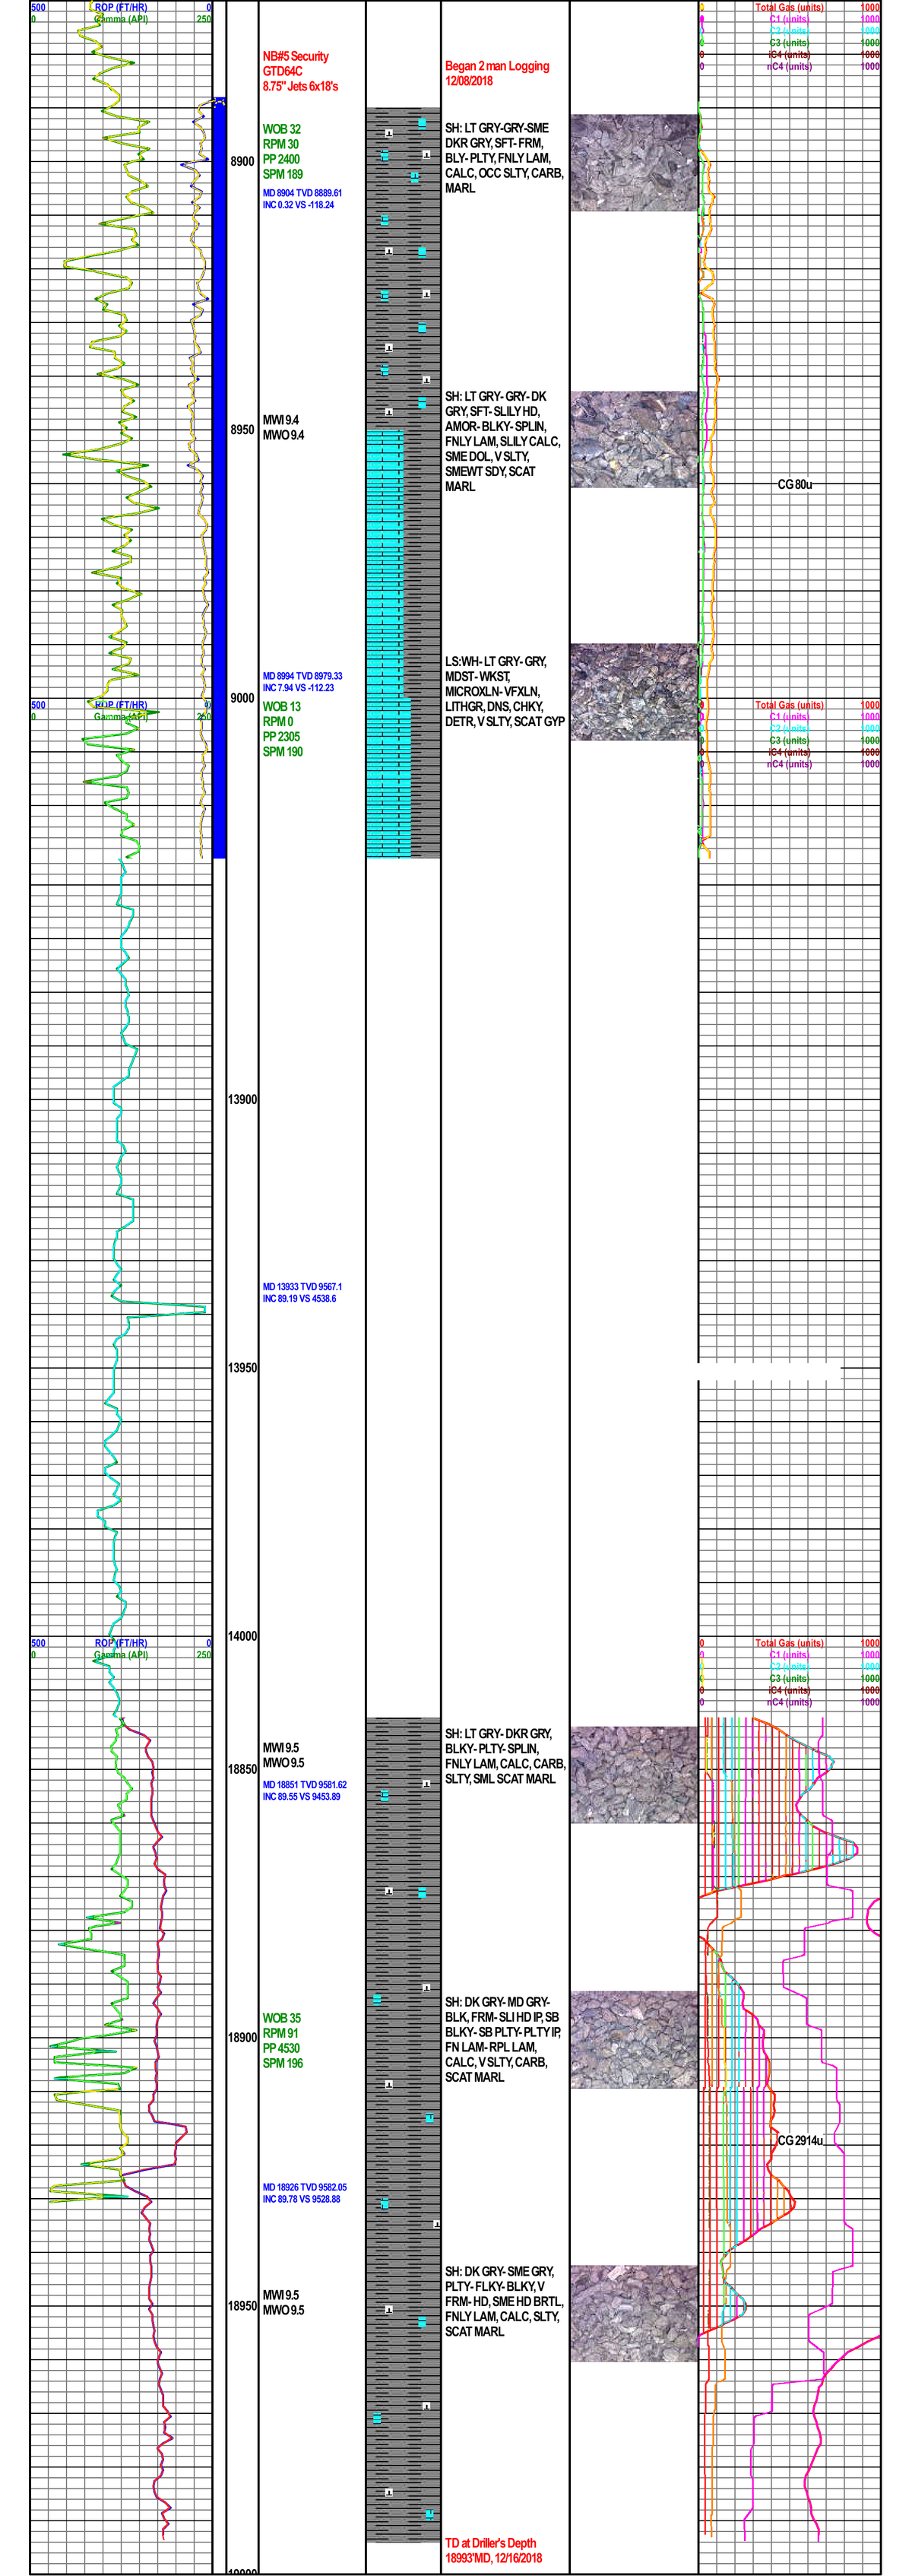

[{'image': 'D:\\ROGII\\test_images_01\\00da89e8.tif',
  'curves': 256,
  'overlay': 'predictions_analysis_results\\00da89e8_overlay.png',
  'coordinates': 'predictions_analysis_results\\00da89e8_curves.json'}]

In [6]:
palette = [
    (255, 35, 35),
    (0, 235, 255),
    (255, 220, 0),
    (255, 0, 220),
    (80, 255, 70),
    (255, 130, 0),
]
summary = []

for image_path in example_paths:
    image = np.asarray(Image.open(image_path).convert("RGB"))
    probability = predict(image)
    curves = curves_from_mask(probability >= int(THRESHOLD * 255), image)
    del probability

    overlay = Image.fromarray(image)
    del image
    draw = ImageDraw.Draw(overlay)
    for curve_index, curve in enumerate(curves):
        color = palette[curve_index % len(palette)]
        segment = []
        for point in curve + [None]:
            if point is None:
                if len(segment) > 1:
                    draw.line(segment, fill=color, width=3)
                elif segment:
                    x, y = segment[0]
                    draw.ellipse((x - 2, y - 2, x + 2, y + 2), fill=color)
                segment = []
            else:
                segment.append((int(point[0]), int(point[1])))

    stem = image_path.stem
    overlay_path = RESULTS_DIR / f"{stem}_overlay.png"
    curves_path = RESULTS_DIR / f"{stem}_curves.json"
    overlay.save(overlay_path)
    curves_path.write_text(
        json.dumps(curves, ensure_ascii=False, separators=(",", ":")),
        encoding="utf-8",
    )

    summary.append(
        {
            "image": str(image_path),
            "curves": len(curves),
            "overlay": str(overlay_path),
            "coordinates": str(curves_path),
        }
    )
    print(f"{image_path.name}: кривых {len(curves)}")
    print(f"  overlay: {overlay_path.resolve()}")
    print(f"  curves:  {curves_path.resolve()}")

    preview_height = min(1600, overlay.height)
    if overlay.height <= preview_height:
        preview = overlay.copy()
    else:
        starts = sorted({0, (overlay.height - preview_height) // 2, overlay.height - preview_height})
        preview = Image.new("RGB", (overlay.width, preview_height * len(starts)))
        for panel, start in enumerate(starts):
            crop = overlay.crop((0, start, overlay.width, start + preview_height))
            preview.paste(crop, (0, panel * preview_height))
    preview.thumbnail((1200, 3600), Image.Resampling.LANCZOS)
    preview_path = RESULTS_DIR / f"{stem}_preview.png"
    preview.save(preview_path)
    print(f"  preview: {preview_path.resolve()}")
    display(preview)

    del curves, overlay, preview

summary